In [1]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
import numpy as np
import matplotlib.pyplot as plt

In [2]:
train = r"Downloads/Pneumonia X Ray-20221031T100017Z-001 (1)/Pneumonia X Ray/train"
test = r"Downloads/Pneumonia X Ray-20221031T100017Z-001 (1)/Pneumonia X Ray/test"

In [3]:
train_gen = ImageDataGenerator(rescale = 1./255).flow_from_directory(train,target_size = (224,224),batch_size = 32,class_mode = 'categorical')
test_gen = ImageDataGenerator(rescale = 1./255).flow_from_directory(test,target_size = (224,224),batch_size = 32,class_mode = 'categorical')

Found 3937 images belonging to 2 classes.
Found 624 images belonging to 2 classes.


In [4]:
class_names = list(train_gen.class_indices.keys())

print(class_names)

['NORMAL', 'PNEUMONIA']


In [16]:
model = Sequential([
   Conv2D(64, (3,3), activation='relu', input_shape=(224,224,3)),
    MaxPooling2D((2,2)),

    Conv2D(32, (3,3), activation='relu'),
    MaxPooling2D((2,2)),

    Conv2D(16, (3,3), activation='relu'),
    MaxPooling2D((2,2)),

    Flatten(),

    Dense(128, activation='relu'),
    Dense(2, activation='softmax')
    
])

In [17]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [18]:
history = model.fit(
    train_gen,
    validation_data=test_gen,
    epochs=5,
    verbose=1
)

Epoch 1/5
124/124 ━━━━━━━━━━━━━━━━━━━━ 82s 645ms/step - accuracy: 0.8877 - loss: 0.2479 - val_accuracy: 0.8061 - val_loss: 0.5417
Epoch 2/5
124/124 ━━━━━━━━━━━━━━━━━━━━ 69s 556ms/step - accuracy: 0.9573 - loss: 0.1117 - val_accuracy: 0.7564 - val_loss: 0.8273
Epoch 3/5
124/124 ━━━━━━━━━━━━━━━━━━━━ 65s 524ms/step - accuracy: 0.9792 - loss: 0.0608 - val_accuracy: 0.7724 - val_loss: 0.9570
Epoch 4/5
124/124 ━━━━━━━━━━━━━━━━━━━━ 61s 491ms/step - accuracy: 0.9637 - loss: 0.0967 - val_accuracy: 0.7532 - val_loss: 1.0247
Epoch 5/5
124/124 ━━━━━━━━━━━━━━━━━━━━ 66s 535ms/step - accuracy: 0.9738 - loss: 0.0738 - val_accuracy: 0.7147 - val_loss: 1.4516


In [19]:
x_test,y_test = next(test_gen)
preds = np.argmax(model.predict(x_test[:5]),axis = 1)
actual = np.argmax(y_test[:5],axis = 1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step


In [20]:
print(history.history['accuracy'])
print(history.history['val_accuracy'])

[0.8877317905426025, 0.9573279023170471, 0.9791719317436218, 0.9636779427528381, 0.9738379716873169]
[0.8060897588729858, 0.7564102411270142, 0.7724359035491943, 0.7532051205635071, 0.7147436141967773]


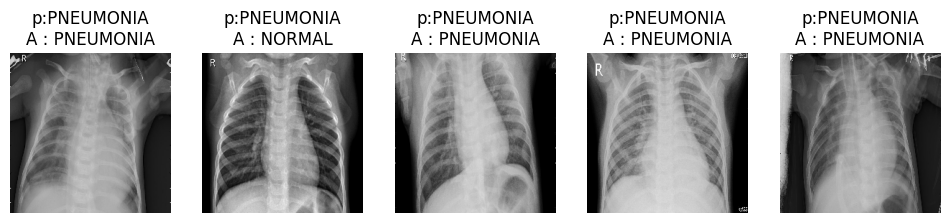

In [21]:
plt.figure(figsize = (12,4))
for i in range(5):
    plt.subplot(1,5,i+1)
    plt.imshow(x_test[i])
    plt.title(f"p:{class_names[preds[i]]}\nA : {class_names[actual[i]]}")
    plt.axis('off')
plt.show()